Frame 0: before / after


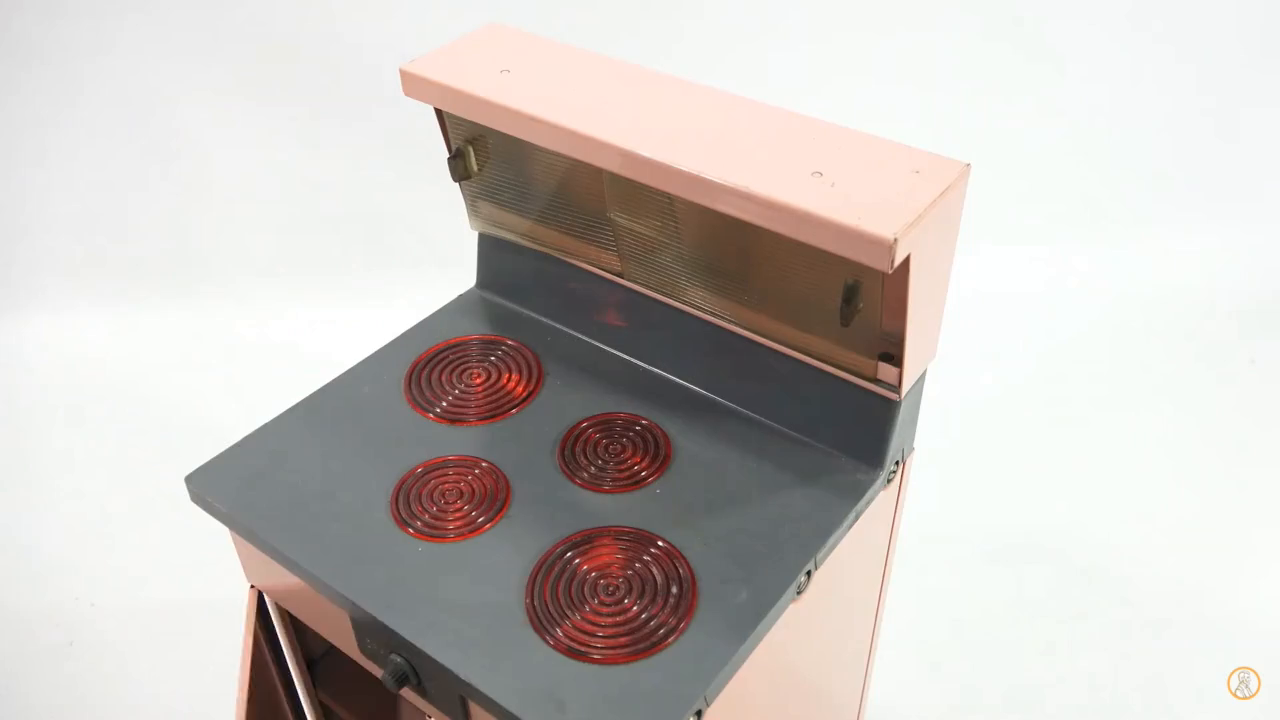

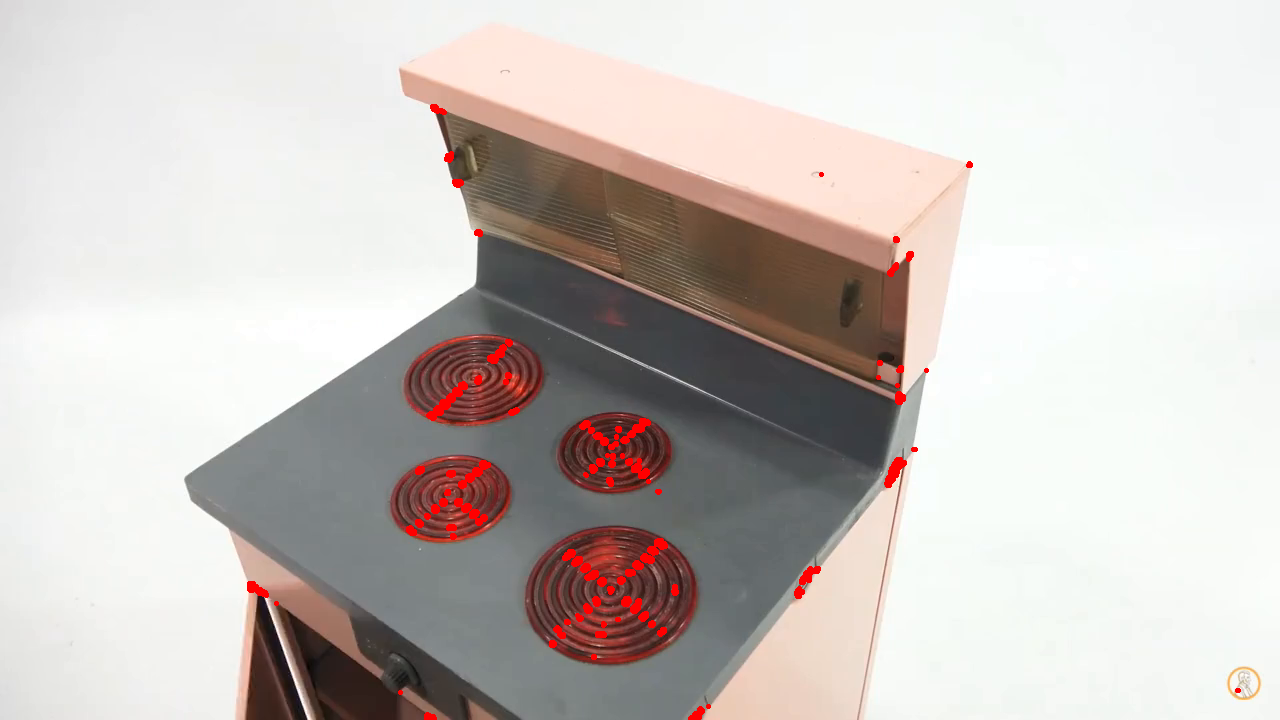

Frame 100: before / after


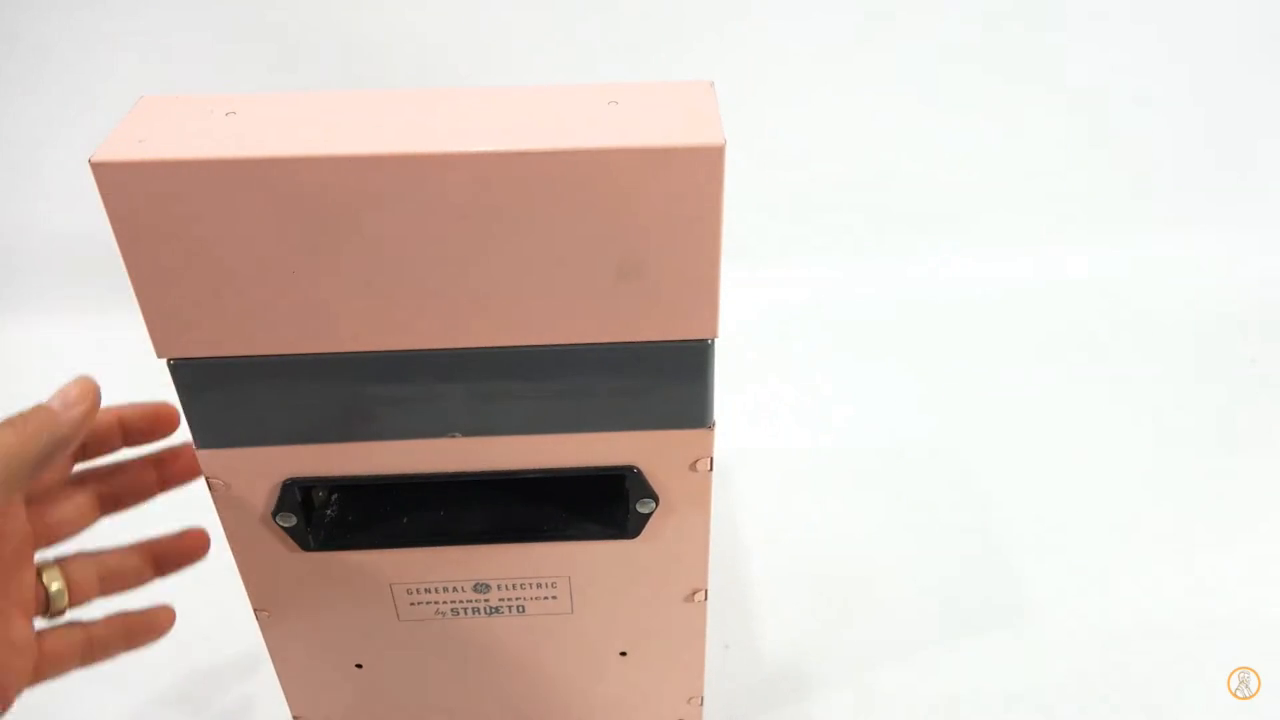

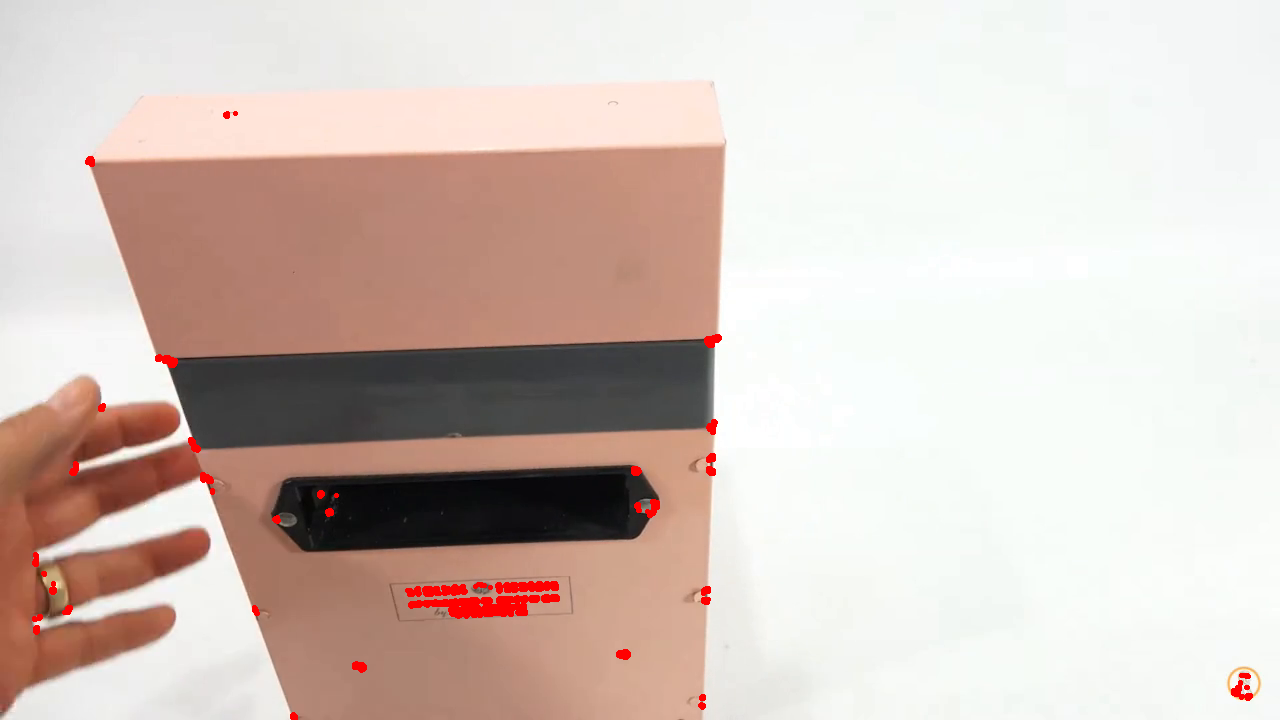

Frame 300: before / after


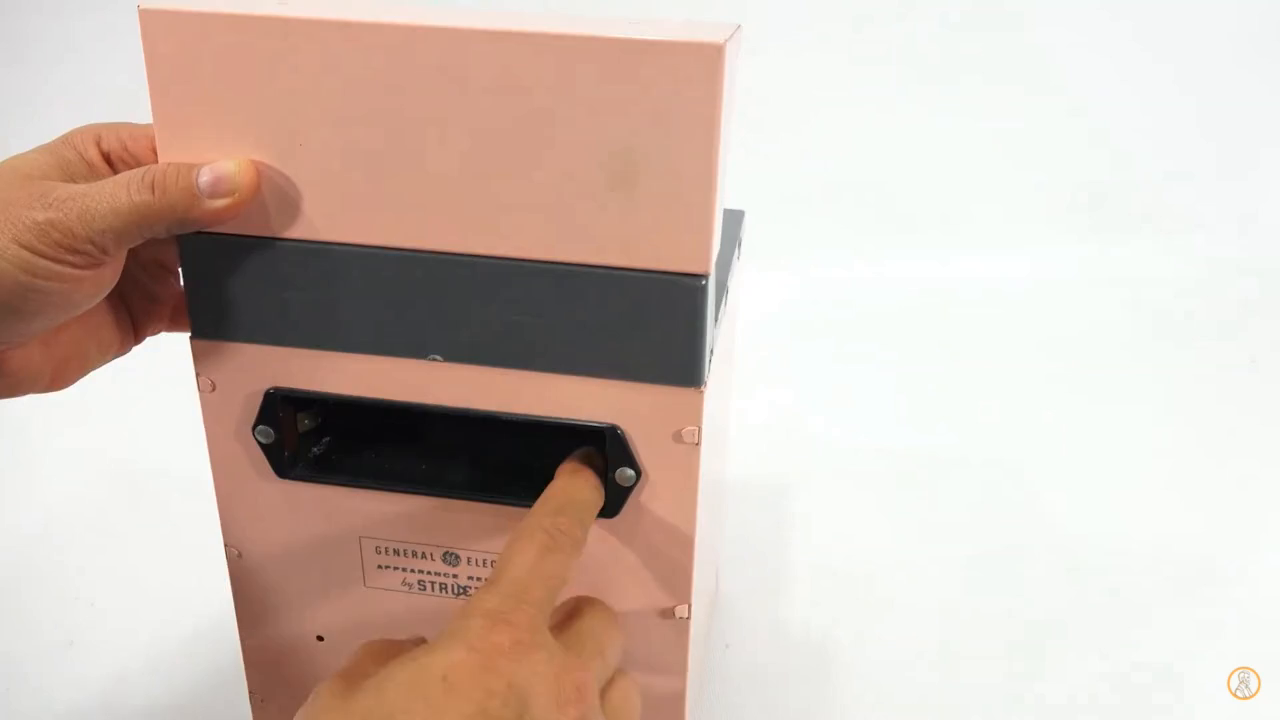

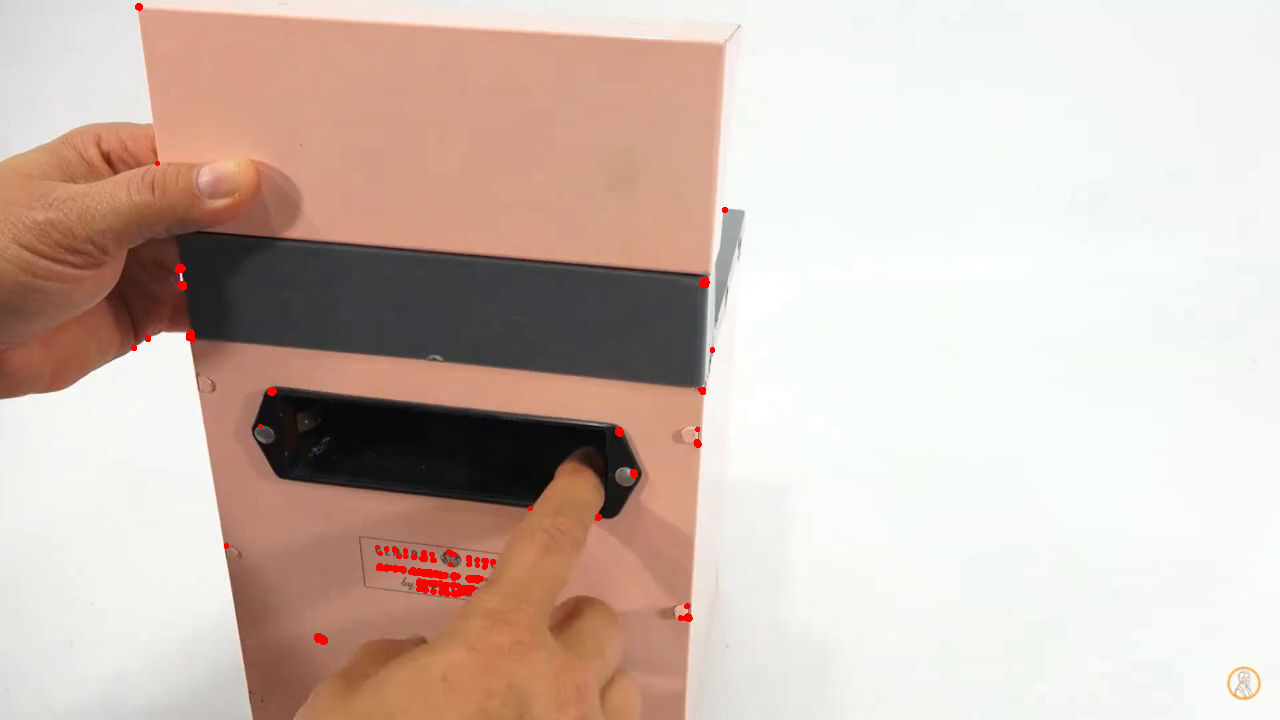

Done. Processed 1049 frames


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
#Lab 3-4: Harris Corner Detection
#Video Processing

#Importing needed libraries
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

VIDEO_PATH = "/content/harris_corner_detection_image_V.mp4"
BLOCK_SIZE = 4
APERTURE_SIZE = 3
K = 0.04
THRESH_RATIO = 0.01
SHOW_FRAMES = [0, 100, 300]

cap = cv2.VideoCapture(VIDEO_PATH)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

out = cv2.VideoWriter("harris_output.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

frame_no = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break

    original = frame.copy()
    gray = np.float32(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))

    harris = cv2.cornerHarris(gray, BLOCK_SIZE, APERTURE_SIZE, K)
    harris = cv2.dilate(harris, None)

    ys, xs = np.where(harris > THRESH_RATIO * harris.max())
    for x, y in zip(xs, ys):
        cv2.circle(frame, (int(x), int(y)), 1, (0, 0, 255), -1)

    out.write(frame)

    if frame_no in SHOW_FRAMES:
        print(f"Frame {frame_no}: before / after")
        cv2_imshow(original)
        cv2_imshow(frame)

    frame_no += 1

cap.release()
out.release()
print("Done. Processed", frame_no, "frames")

files.download("harris_output.mp4")